[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_oos_vol/BA_L4_oos_vol.ipynb)

# BA_L4_oos_vol: One-step volatility forecasts out of sample

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Out-of-sample check of GARCH(1,1)-t volatility forecasts for Bitcoin, Ethereum, the S&P 500 and gold over 19 September - 23 October 2026: realised absolute returns, one-step forecasts with parameters frozen on 18 September 2026, the 18 September forecast path and the realised root mean square return.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Data.** Daily log returns in %: estimation 1 January 2018 – 18 September 2026; evaluation 19 September – 23 October 2026.

**Model.** $r_t = \mu + \varepsilon_t$, $\varepsilon_t = \sigma_t z_t$, with the GARCH(1,1) recursion of Bollerslev (1986)
$$ \sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2 , $$
and $z_t$ i.i.d. (independent and identically distributed) Student-t with $\nu$ degrees of freedom, rescaled to variance 1 (GARCH-t).
$\alpha + \beta$ is the persistence; the parameters are estimated by maximum likelihood.

**Out of sample.** The GARCH-t parameters are frozen on 18 September 2026 (day $T$); only the filter is updated with each new return,
$$ \hat\sigma^2_{t|t-1} = \hat\omega + \hat\alpha\,(r_{t-1} - \hat\mu)^2 + \hat\beta\,\hat\sigma^2_{t-1|t-2}, \qquad t = T+1, \dots, T+H, $$
over 19 September – 23 October 2026: 35 calendar days for crypto, 25 trading days for the S&P 500 and gold.

**How to read** (all in % a day). Bars: realised $|r_t|$; red: one-step forecast $\hat\sigma_{t|t-1}$; dashed blue: the forecast path made on 18 September, $\sqrt{\mathrm{E}_T\sigma^2_{T+h}}$; dotted green: the realised root mean square (RMS) return of the window, $\sqrt{\overline{r^2}}$.

In [5]:
from scipy import stats
from arch import arch_model

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]


R = {k: log_returns(ASSETS[k][0]) for k in ['Bitcoin', 'Ethereum', 'S&P 500', 'Gold']}
print({k: f'{len(r)} days, {r.index[0].date()} - {r.index[-1].date()}' for k, r in R.items()})

{'Bitcoin': '3183 days, 2018-01-01 - 2026-09-18', 'Ethereum': '3183 days, 2018-01-01 - 2026-09-18', 'S&P 500': '2190 days, 2018-01-02 - 2026-09-18', 'Gold': '2269 days, 2018-01-01 - 2026-09-18'}


In [6]:
# GARCH(1,1) with Student-t errors, estimated by maximum likelihood (package arch)
fits = {k: arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off') for k, r in R.items()}
pd.DataFrame({k: {'mu': g.params['mu'], 'omega': g.params['omega'], 'alpha': g.params['alpha[1]'], 'beta': g.params['beta[1]'],
                   'alpha + beta': g.params['alpha[1]'] + g.params['beta[1]'], 'nu': g.params['nu']} for k, g in fits.items()}).round(4)

,Bitcoin,Ethereum,S&P 500,Gold
mu,0.0563,0.0623,0.1109,0.0535
omega,0.1442,0.5495,0.0352,0.0147
alpha,0.0761,0.1175,0.1616,0.0615
beta,0.9239,0.8825,0.8194,0.9308
alpha + beta,1.0000,1.0000,0.9810,0.9923
nu,3.1260,3.1928,5.8454,4.0634


In [7]:
lam = 0.94     # RiskMetrics decay


def ewma_forecasts(r, lam=lam):
    # one-step EWMA variance forecasts: value at t = forecast for day t made at the end of day t-1;
    # started at the variance of the first 250 days; the last element is the forecast for the day after the sample
    v = r.iloc[:250].var(); out = []
    for x in r.values:
        out.append(v)
        v = lam * v + (1 - lam) * x ** 2
    return pd.Series(out, index=r.index), v

In [8]:
T0, T1 = pd.Timestamp(END), pd.Timestamp('2026-10-23')
oos_rows, paths, onestep = {}, {}, {}
for k, (sym, A, col) in ASSETS.items():
    r_all = (100 * np.log(closes(sym, T1)).diff()).dropna().loc['2018-01-01':]
    ins, oos = r_all.loc[:T0], r_all.loc[T0 + pd.Timedelta(days=1):]
    prm = fits[k].params
    H = len(oos)
    path_ = fits[k].forecast(horizon=H, reindex=False).variance.values[-1]       # E_T[sigma^2_{T+h}], h = 1..H
    sig = arch_model(r_all, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fix(prm).conditional_volatility.loc[oos.index]
    ewk = ewma_forecasts(r_all)[0].loc[oos.index]                                  # EWMA one-step variance forecasts
    const = ins.var()                                                              # Normal: full-sample variance
    rv = np.sqrt(A * (oos ** 2).mean())
    oos_rows[k] = {'days in the window': H, 'return over the window (%)': oos.sum(),
                   'GARCH-t sigma_(T+1), 18 Sep (% a year)': np.sqrt(A * path_[0]),
                   'GARCH-t, average over the window (% a year)': np.sqrt(A * path_.mean()),
                   'EWMA, 18 Sep (% a year)': np.sqrt(A * ewk.iloc[0]),
                   'realised, 19 Sep - 23 Oct (% a year)': rv}
    paths[k] = pd.Series(np.sqrt(A * path_), index=oos.index)
    onestep[k] = (oos, sig, A, ewk, const, prm)

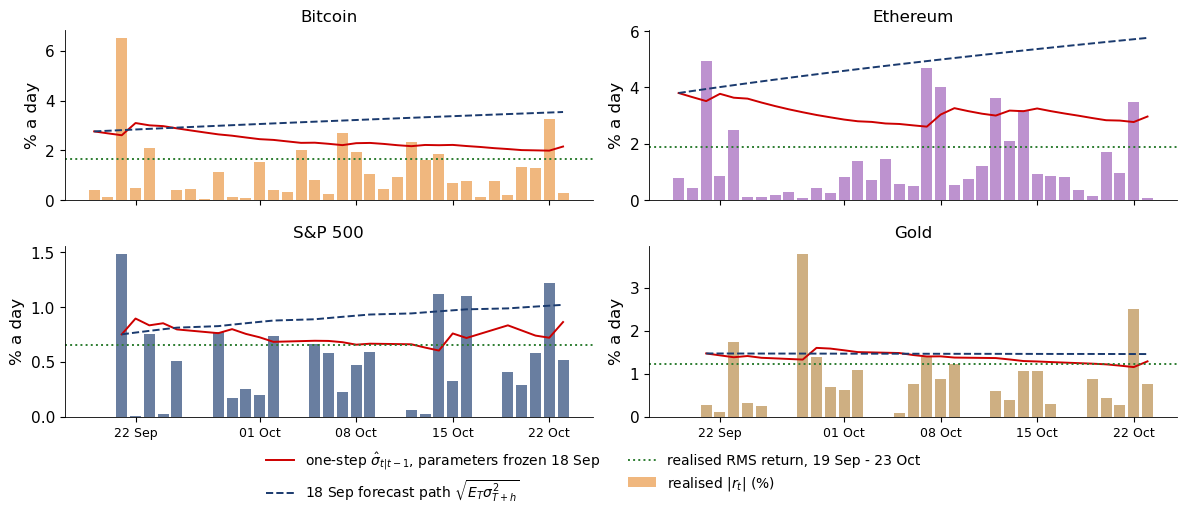

In [9]:
import matplotlib.dates as mdates
fig, axs = plt.subplots(2, 2, figsize=(12, 5.2), sharex=True)
for ax, (k, (oos_k, sig, A, ewk, const, prm_k)) in zip(axs.flat, onestep.items()):
    ax.bar(oos_k.index, oos_k.abs(), width=0.8, color=ASSETS[k][2], alpha=0.65, label=('realised $|r_t|$ (%)' if k == 'Bitcoin' else None))
    ax.plot(sig.index, sig, color=RED, lw=1.4, label=(r'one-step $\hat\sigma_{t|t-1}$, parameters frozen 18 Sep' if k == 'Bitcoin' else None))
    ax.plot(paths[k].index, paths[k] / np.sqrt(A), color=BLUE, ls='--', lw=1.4,
            label=(r'18 Sep forecast path $\sqrt{E_T\sigma^2_{T+h}}$' if k == 'Bitcoin' else None))
    ax.axhline(np.sqrt((oos_k ** 2).mean()), color=GREEN, ls=':', lw=1.4, label=('realised RMS return, 19 Sep - 23 Oct' if k == 'Bitcoin' else None))
    ax.set_title(k); ax.set_ylabel('% a day'); ax.tick_params(axis='x', labelsize=9)
for ax in axs[1]:
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
legend_below(fig, ncol=2); fig.tight_layout(rect=(0, 0.11, 1, 1))
save_fig(fig, 'ba_oos_vol')

**Key numbers** (as on the slides): volatilities annualised, in % a year.

In [10]:
b = onestep['Bitcoin'][0]
print(f'Bitcoin largest daily return in the window: {b.max():+.2f}% on {b.idxmax().date()}')
for k in ['Bitcoin', 'Ethereum']:
    pr = fits[k].params
    print(f'{k}: persistence alpha + beta = {pr["alpha[1]"] + pr["beta[1]"]:.10f} (at the bound 1), omega = {pr["omega"]:.3f}')
pd.DataFrame(oos_rows).round(2)

Bitcoin largest daily return in the window: +6.51% on 2026-09-21
Bitcoin: persistence alpha + beta = 1.0000000000 (at the bound 1), omega = 0.144
Ethereum: persistence alpha + beta = 1.0000000000 (at the bound 1), omega = 0.550


,Bitcoin,Ethereum,S&P 500,Gold
days in the window,35.00,35.00,25.00,25.00
return over the window (%),0.21,-9.11,-0.35,-9.26
"GARCH-t sigma_(T+1), 18 Sep (% a year)",52.75,72.64,11.91,23.32
"GARCH-t, average over the window (% a year)",60.64,93.20,14.36,23.21
"EWMA, 18 Sep (% a year)",44.90,58.83,10.40,23.86
"realised, 19 Sep - 23 Oct (% a year)",31.80,36.15,10.32,19.32
